In [1]:
########################################################
###################### Importierte Packete #############
########################################################

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc                                                   # To use a LaTeX font
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.colors import rgb2hex

#import csv

import numpy as np
from numpy import diff

import pandas as pd

import scipy
from scipy import stats
import scipy.constants as sc
from scipy import ndimage
import scipy.signal
from scipy.interpolate import interp1d

import statsmodels.api as sm
from statsmodels.graphics.gofplots import qqplot

from mpl_toolkits import mplot3d                                            # Um 3D Plots zu machen

import itertools

import os

##### Saving/packing of data
import pickle

##### To create colour gradients
from colour import Color

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.battery.analysis import Extract_Charge_Discharge_Capacities
from scientific_utils.battery.analysis import Extract_Potential_Drop_Applied_Current
from scientific_utils.battery.analysis import Extract_Potential_Drop_During_OCV
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.general.plotting import Matplotlib_XvsY
from scientific_utils.general.plotting import Matplotlib_XvsY1Y2

In [3]:
# create the output folder if it does not exist yet
if not os.path.exists('./images/'):
    os.mkdir('./images/')

In [4]:
#########################################################
##################### Start of the code ##################
#########################################################

In [5]:
########## Open the .pkl file ########
########## Open the CP steps
##### CP charge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_charge_equidistant.pkl', 'rb') as f:
    list_of_dataframes_of_CP_charge_equidistant = pickle.load(f)    

##### CP discharge steps
with open('../data/Batt15/processed/list_of_dataframes_of_CP_discharge_equidistant.pkl', 'rb') as f:
    list_of_dataframes_of_CP_discharge_equidistant = pickle.load(f)
    
########## Load the OCV steps after the CP step
##### OCVs after a Charging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_of_OCV_after_CP_step_charge.pkl', 'rb') as f:
    list_of_dataframes_of_OCV_after_CP_step_charge = pickle.load(f) 

##### OCVs after a Discharging step in the C Rate Test
with open('../data/Batt15/processed/list_of_dataframes_of_OCV_after_CP_step_discharge.pkl', 'rb') as f:
    list_of_dataframes_of_OCV_after_CP_step_discharge = pickle.load(f) 
    

########## Create a list with more information about the data for plotting later #######
list_RateTest_labels = [0.10, 0.33, 1.00]


In [6]:
#print(list_of_dataframes_of_CP_discharge_equidistant_cycling[0])
#print(list_of_dataframes_OCV_after_CP_step_discharge_cycling[0])

In [7]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list


In [8]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

In [9]:
############################### Defining Functions #################################

In [10]:
############################### Total Charging/Discharging Capacities #################################

In [11]:
#list_of_dataframes_of_CP_charge_equidistant
#list_of_dataframes_of_CP_discharge_equidistant
#list_of_dataframes_of_OCV_after_CP_step_charge
#list_of_dataframes_of_OCV_after_CP_step_discharge


In [12]:
# Deleting unneccesary Data of CP charge
#list_of_dataframes = list_of_dataframes_of_CP_charge_equidistant

#list_of_dataframes_of_CP_charge_equidistant_cleaned = DeleteListEntries(list_of_dataframes)

list_of_dataframes_of_CP_charge_equidistant_cleaned = list_of_dataframes_of_CP_charge_equidistant

#print(list_of_dataframes_of_CP_charge_equidistant_cleaned)

In [13]:
# Deleting unneccesary Data of OCV after charge
#list_of_dataframes = list_of_dataframes_of_OCV_after_CP_step_charge

#list_of_dataframes_of_OCV_after_CP_step_charge_cleaned = DeleteListEntries(list_of_dataframes)

list_of_dataframes_of_OCV_after_CP_step_charge_cleaned = list_of_dataframes_of_OCV_after_CP_step_charge

#print(list_of_dataframes_of_OCV_after_CP_step_charge_cleaned)

In [14]:
# Deleting unneccesary Data of CP discharge
#list_of_dataframes = list_of_dataframes_of_CP_discharge_equidistant

#list_of_dataframes_of_CP_discharge_equidistant_cleaned = DeleteListEntries(list_of_dataframes)

list_of_dataframes_of_CP_discharge_equidistant_cleaned = list_of_dataframes_of_CP_discharge_equidistant

#print(list_of_dataframes_of_CP_discharge_equidistant_cleaned)

In [15]:
# Deleting unneccesary Data of OCV after discharge
#list_of_dataframes = list_of_dataframes_of_OCV_after_CP_step_discharge

#list_of_dataframes_of_OCV_after_CP_step_discharge_cleaned = DeleteListEntries(list_of_dataframes)

list_of_dataframes_of_OCV_after_CP_step_discharge_cleaned = list_of_dataframes_of_OCV_after_CP_step_discharge

#print(list_of_dataframes_of_OCV_after_CP_step_discharge_cleaned)

In [16]:
list_of_dataframes_charging_steps = list_of_dataframes_of_CP_charge_equidistant_cleaned
values_column_name_charge = 'Q charge/mA.h'
list_of_dataframes_discharging_steps = list_of_dataframes_of_CP_discharge_equidistant_cleaned
values_column_name_discharge = 'Q discharge/mA.h'

dataframes_of_charge_discharge_capacities_per_rate = Extract_Charge_Discharge_Capacities(list_of_dataframes_charging_steps, values_column_name_charge, list_of_dataframes_discharging_steps, values_column_name_discharge, list_of_labels=list_RateTest_labels)

#print(dataframes_of_charge_discharge_capacities_per_rate)

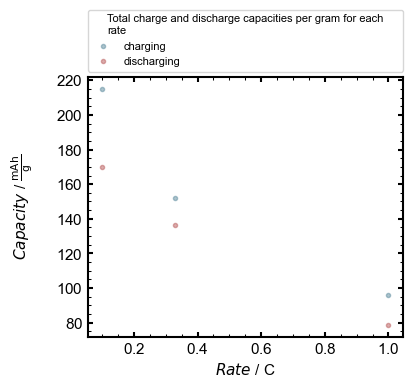

In [17]:
dataframe = dataframes_of_charge_discharge_capacities_per_rate
x_values_column_name = 'Rate / C'
y_values_column_name_first = 'Charge Capacity / mAh/g'
y_values_column_name_second = 'Discharge Capacity / mAh/g'
label_y_first = 'charging'
label_y_second = 'discharging'
y_ax_label = r'$ Capacity $ / $\frac{\mathsf{mAh}}{\mathsf{g}}$'
x_ax_label = r'$ Rate $ / C'
save = 1
name_figure = 'Total_charge_and_discharge_capacities_per_gram_for_each_rate' 
legend_title = 'Total charge and discharge capacities per gram for each rate'

Matplotlib_XvsY1Y2(dataframe, x_values_column_name, y_values_column_name_first, y_values_column_name_second, label_y_first, label_y_second, y_ax_label, x_ax_label, save, name_figure, legend_title)

In [18]:
################################ Potential Drop CP to OCV #################################

In [19]:
list_of_dataframes_charging_cycles = list_of_dataframes_of_CP_charge_equidistant_cleaned
column_names_charging = '<Ewe>/V'
list_of_dataframes_discharging_cycles = list_of_dataframes_of_CP_discharge_equidistant_cleaned
column_names_discharging = '<Ewe>/V'
list_of_dataframes_OCV_after_charging = list_of_dataframes_of_OCV_after_CP_step_charge_cleaned
column_names_ocv_charging = 'Ewe/V'
list_of_dataframes_OCV_after_discharging = list_of_dataframes_of_OCV_after_CP_step_discharge_cleaned
column_names_ocv_discharging = 'Ewe/V'

dataframes_of_potential_drop_between_CP_and_OCV_per_rate = Extract_Potential_Drop_Applied_Current(list_of_dataframes_charging_cycles, column_names_charging, list_of_dataframes_discharging_cycles, column_names_discharging, list_of_dataframes_OCV_after_charging, column_names_ocv_charging, list_of_dataframes_OCV_after_discharging, column_names_ocv_discharging, list_of_labels=list_RateTest_labels)

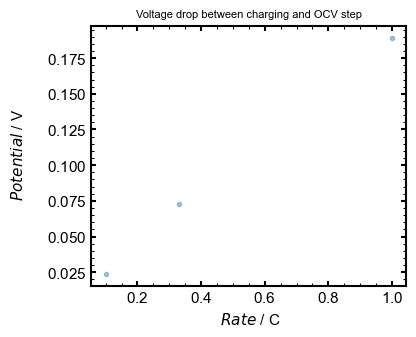

In [20]:
dataframe = dataframes_of_potential_drop_between_CP_and_OCV_per_rate
x_values_column_name = 'Rate / C'
y_values_column_name = 'DeltaV CP charge to OCV'
y_ax_label = r' $ Potential $ / V'
x_ax_label = r' $ Rate $ / C'
label_graph = 'charge'
save = 1 
name_figure = 'Voltage_drop_between_charging_and_OCV_step'
legend_title = 'Voltage drop between charging and OCV step'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure,legend_title)

[       Q charge/mA.h   <Ewe>/V
 0       0.000000e+00  2.040372
 1       9.839335e-09  2.040396
 2       1.967867e-08  2.040419
 3       2.951800e-08  2.040443
 4       3.935734e-08  2.040466
 ...              ...       ...
 70388   1.807903e+00  3.699735
 70389   1.807918e+00  3.699758
 70390   1.807934e+00  3.699782
 70391   1.807947e+00  3.699805
 70392   1.807947e+00  3.699829
 
 [70393 rows x 2 columns],
        Q charge/mA.h   <Ewe>/V
 0       0.000000e+00  3.077890
 1       3.892214e-07  3.077932
 2       7.784429e-07  3.077973
 3       1.167664e-06  3.078014
 4       1.556886e-06  3.078055
 ...              ...       ...
 15078   1.277154e+00  3.699643
 15079   1.277198e+00  3.699684
 15080   1.277243e+00  3.699725
 15081   1.277291e+00  3.699767
 15082   1.277328e+00  3.699808
 
 [15083 rows x 2 columns],
       Q charge/mA.h   <Ewe>/V
 0          0.000000  3.265544
 1          0.000006  3.265682
 2          0.000012  3.265820
 3          0.000018  3.265958
 4          0.00002

[      mode  error        time/s     Ewe/V     Ece/V  Analog IN 1/V  Ewe-Ece/V  \
 0      3.0    0.0  35195.863554  3.675942  0.000995       0.000056   3.674946   
 1      3.0    0.0  35198.363554  3.672458  0.000755       0.000118   3.671703   
 2      3.0    0.0  35200.863554  3.671194  0.000858       0.000118   3.670336   
 3      3.0    0.0  35203.363554  3.670227  0.000583       0.000072   3.669645   
 4      3.0    0.0  35205.863554  3.669567  0.000755       0.000072   3.668812   
 ...    ...    ...           ...       ...       ...            ...        ...   
 4316   3.0    0.0  45985.863574  3.610357  0.000548       0.000003   3.609809   
 4317   3.0    0.0  45988.363574  3.610433  0.000755       0.000087   3.609679   
 4318   3.0    0.0  45990.863574  3.610391  0.000617       0.000072   3.609774   
 4319   3.0    0.0  45993.363574  3.610349  0.000789       0.000064   3.609561   
 4320   3.0    0.0  45995.863574  3.610273  0.000514       0.000156   3.609759   
 
       Unnamed

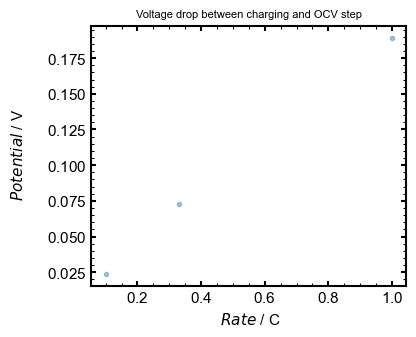

In [21]:
display(list_of_dataframes_of_CP_charge_equidistant_cleaned)
display(list_of_dataframes_of_OCV_after_CP_step_charge_cleaned)

dataframe = dataframes_of_potential_drop_between_CP_and_OCV_per_rate
x_values_column_name = 'Rate / C'
y_values_column_name = 'DeltaV CP charge to OCV'
y_ax_label = r' $ Potential $ / V'
x_ax_label = r' $ Rate $ / C'
label_graph = 'charge'
save = 1 
name_figure = 'Voltage_drop_between_charging_and_OCV_step'
legend_title = 'Voltage drop between charging and OCV step'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure,legend_title)

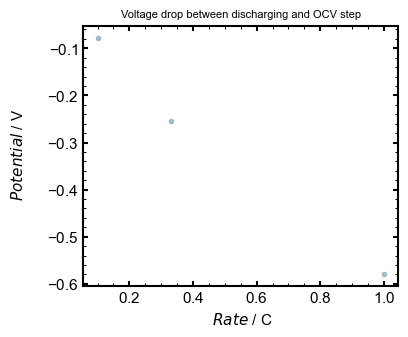

In [22]:
dataframe = dataframes_of_potential_drop_between_CP_and_OCV_per_rate
x_values_column_name = 'Rate / C'
y_values_column_name = 'DeltaV CP discharge to OCV'
y_ax_label = ' $ Potential $ / V'
x_ax_label = ' $ Rate $ / C'
label_graph = 'discharge'
save = 1 
name_figure = 'Voltage_drop_between_discharging_and_OCV step'
legend_title = 'Voltage drop between discharging and OCV step'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure, legend_title)

In [23]:
############################# Potential difference between Start of OCV and End of OCV ############################

In [24]:
list_of_dataframes_OCV_after_charge = list_of_dataframes_of_OCV_after_CP_step_charge_cleaned
column_names_ocv_charging = 'Ewe/V'
list_of_dataframes_OCV_after_discharge = list_of_dataframes_of_OCV_after_CP_step_discharge_cleaned
column_names_ocv_discharging = 'Ewe/V'

dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_rate = Extract_Potential_Drop_During_OCV(list_of_dataframes_OCV_after_charge, column_names_ocv_charging, list_of_dataframes_OCV_after_discharge, column_names_ocv_discharging, list_of_labels=list_RateTest_labels)

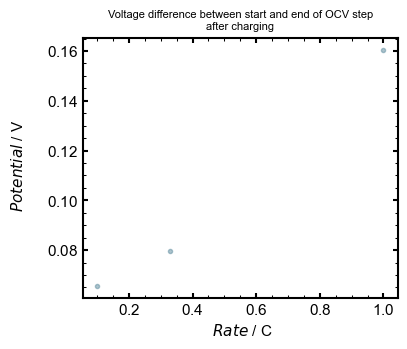

In [25]:
dataframe = dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_rate
x_values_column_name = 'Rate / C'
y_values_column_name = 'Potential Difference OCV charge at end'
y_ax_label = ' $ Potential $ / V'
x_ax_label = ' $ Rate $ / C'
label_graph = 'charge'
save = 1
name_figure = 'Voltage_difference_between_start_and_end_of_OCV_step_after_charging'
legend_title = 'Voltage difference between start and end of OCV step after charging'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure, legend_title)

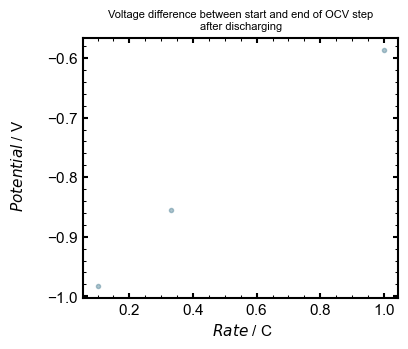

In [26]:
dataframe = dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_rate
x_values_column_name = 'Rate / C'
y_values_column_name = 'Potential Difference OCV discharge at end'
y_ax_label = ' $ Potential $ / V'
x_ax_label = ' $ Rate $ / C'
label_graph = 'discharge'
save = 1
name_figure = 'Voltage_difference_between_start_and_end_of_OCV_step_after_discharging'
legend_title = 'Voltage difference between start and end of OCV step after discharging'

Matplotlib_XvsY(dataframe, x_values_column_name, y_values_column_name, y_ax_label, x_ax_label, label_graph, save, name_figure, legend_title)

In [27]:
########################## Saving of the generated Dataframes ####################

In [28]:
########## Save the data as .pkl ##########
with open('../data/Batt15/processed/dataframes_of_charge_discharge_capacities_per_rate.pkl', 'wb') as f:
    pickle.dump(dataframes_of_charge_discharge_capacities_per_rate, f)

with open('../data/Batt15/processed/dataframes_of_potential_drop_between_CP_and_OCV_per_rate.pkl', 'wb') as f:
    pickle.dump(dataframes_of_potential_drop_between_CP_and_OCV_per_rate, f) 
    
with open('../data/Batt15/processed/dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_rate.pkl', 'wb') as f:
    pickle.dump(dataframes_of_potential_drop_beginning_OCV_and_end_OCV_per_rate, f) 